## Step 1: Imports & Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

df = pd.read_csv('creditcard.csv')

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Step 2 - Dataset Exploration

In [5]:
print("Class Distribution:\n", df['Class'].value_counts(normalize=True))
print("Missing values:", df.isnull().sum().max())
print("Duplicates:", df.duplicated().sum())
print("Descriptive Stats:\n", df.describe())

Class Distribution:
 Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64
Missing values: 0
Duplicates: 1081
Descriptive Stats:
                 Time            V1            V2            V3            V4  \
count  284807.000000  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean    94813.859575  1.168375e-15  3.416908e-16 -1.379537e-15  2.074095e-15   
std     47488.145955  1.958696e+00  1.651309e+00  1.516255e+00  1.415869e+00   
min         0.000000 -5.640751e+01 -7.271573e+01 -4.832559e+01 -5.683171e+00   
25%     54201.500000 -9.203734e-01 -5.985499e-01 -8.903648e-01 -8.486401e-01   
50%     84692.000000  1.810880e-02  6.548556e-02  1.798463e-01 -1.984653e-02   
75%    139320.500000  1.315642e+00  8.037239e-01  1.027196e+00  7.433413e-01   
max    172792.000000  2.454930e+00  2.205773e+01  9.382558e+00  1.687534e+01   

                 V5            V6            V7            V8            V9  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070

## Step 3 - Correct Preprocessing and Data Leakage

In [7]:
# Split before scaling, define base pipeline
X = df.drop('Class', axis=1)
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

pipeline_base = Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=1000))])

## Step 4 - Re-run Baseline Logistic Regression

In [9]:
pipeline_base.fit(X_train, y_train)
y_pred_base = pipeline_base.predict(X_test)
print("Baseline Confusion Matrix:\n", confusion_matrix(y_test, y_pred_base))
print(classification_report(y_test, y_pred_base))

Baseline Confusion Matrix:
 [[56851    13]
 [   36    62]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.63      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



## Step 5 - Re-run Class-Weighted Logistic Regression

In [11]:
pipeline_weighted = Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(class_weight='balanced', max_iter=1000))])
pipeline_weighted.fit(X_train, y_train)
y_pred_weighted = pipeline_weighted.predict(X_test)
print("Weighted Confusion Matrix:\n", confusion_matrix(y_test, y_pred_weighted))
print(classification_report(y_test, y_pred_weighted))

Weighted Confusion Matrix:
 [[55478  1386]
 [    8    90]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



## Step 6 - ROC Curve and ROC-AUC

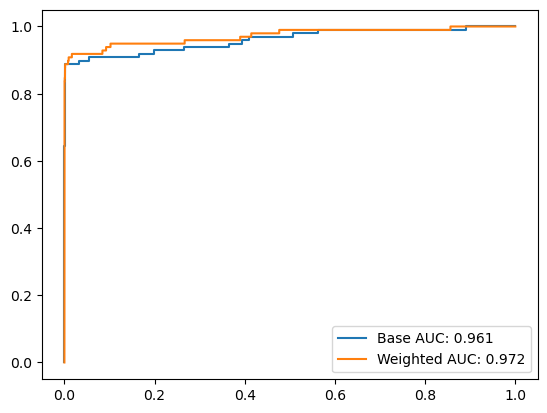

In [13]:
y_prob_base = pipeline_base.predict_proba(X_test)[:, 1]
y_prob_weighted = pipeline_weighted.predict_proba(X_test)[:, 1]

fpr_b, tpr_b, _ = roc_curve(y_test, y_prob_base)
fpr_w, tpr_w, _ = roc_curve(y_test, y_prob_weighted)

plt.plot(fpr_b, tpr_b, label=f'Base AUC: {roc_auc_score(y_test, y_prob_base):.3f}')
plt.plot(fpr_w, tpr_w, label=f'Weighted AUC: {roc_auc_score(y_test, y_prob_weighted):.3f}')
plt.legend(); plt.show()

## Step 7 - Precision-Recall Curve and Average Precision

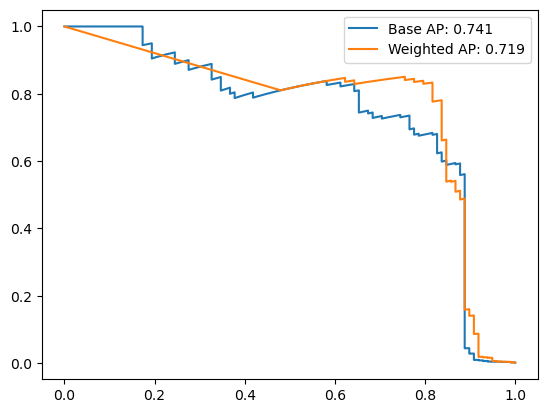

In [15]:
p_b, r_b, _ = precision_recall_curve(y_test, y_prob_base)
p_w, r_w, _ = precision_recall_curve(y_test, y_prob_weighted)

plt.plot(r_b, p_b, label=f'Base AP: {average_precision_score(y_test, y_prob_base):.3f}')
plt.plot(r_w, p_w, label=f'Weighted AP: {average_precision_score(y_test, y_prob_weighted):.3f}')
plt.legend(); plt.show()

## Step 8 - Stratified K-Fold Cross-Validation

In [17]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Step 9 - Hyperparameter Tuning (GridSearchCV)

In [19]:
param_grid = {'lr__C': [0.1, 1, 10]}
grid = GridSearchCV(pipeline_weighted, param_grid, cv=skf, scoring='average_precision', return_train_score=True)
grid.fit(X_train, y_train)

print("Best Params:", grid.best_params_)
print("Cross-Validation Average Precision scores:", grid.cv_results_['mean_test_score'])

Best Params: {'lr__C': 1}
Cross-Validation Average Precision scores: [0.75639561 0.75713608 0.75679393]


## Step 10 - Test Alternative Models

In [21]:
# Using pipelines to prevent leakage here as well
dt = Pipeline([('scaler', StandardScaler()), ('dt', DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42))])
rf = Pipeline([('scaler', StandardScaler()), ('rf', RandomForestClassifier(class_weight='balanced', max_depth=5, n_estimators=50, random_state=42))])

dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('rf',
                 RandomForestClassifier(class_weight='balanced', max_depth=5,
                                        n_estimators=50, random_state=42))])

## Step 11 - Additional Imbalance Strategy (Threshold Tuning)

In [ ]:
from sklearn.model_selection import cross_val_predict

# 1. Get out-of-fold predictions on the TRAINING set
y_train_prob_rf = cross_val_predict(rf, X_train, y_train, cv=skf, method='predict_proba')[:, 1]
p_rf_train, r_rf_train, thresholds_train = precision_recall_curve(y_train, y_train_prob_rf)

# 2. Find optimal threshold using TRAINING data
optimal_idx = (2 * p_rf_train * r_rf_train / (p_rf_train + r_rf_train + 1e-9)).argmax()
optimal_threshold = thresholds_train[optimal_idx] if optimal_idx < len(thresholds_train) else 0.5
print(f"Optimal Threshold (from training CV): {optimal_threshold:.4f}")

# 3. Apply the threshold to the TEST set probabilities
y_prob_rf = rf.predict_proba(X_test)[:, 1]
y_pred_tuned = (y_prob_rf >= optimal_threshold).astype(int)

## Step 12 - Compare All Models 

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

def get_metrics(y_true, y_pred, y_prob):
    return [
        average_precision_score(y_true, y_prob),
        roc_auc_score(y_true, y_prob),
        precision_score(y_true, y_pred),
        recall_score(y_true, y_pred),
        f1_score(y_true, y_pred)
    ]

results = pd.DataFrame(
    [
        get_metrics(y_test, y_pred_base, y_prob_base),
        get_metrics(y_test, y_pred_weighted, y_prob_weighted),
        get_metrics(y_test, grid.predict(X_test), grid.predict_proba(X_test)[:, 1]),
        get_metrics(y_test, dt.predict(X_test), dt.predict_proba(X_test)[:, 1]),
        get_metrics(y_test, y_pred_tuned, y_prob_rf) # Tuned RF
    ],
    columns=['Avg Precision', 'ROC-AUC', 'Precision', 'Recall', 'F1-Score'],
    index=['Base LR', 'Weighted LR', 'Grid LR', 'Dec Tree', 'Tuned Random Forest']
)

print(results.sort_values(by='Avg Precision', ascending=False))

## Step 13 - Final Test-Set Evaluation

In [ ]:
print(f"Final Evaluation (Random Forest with Threshold = {optimal_threshold:.4f}):")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tuned))
print("\nClassification Report:\n", classification_report(y_test, y_pred_tuned))


* **Metric Interpretations:** Base LR had high precision but poor recall. Class weighting drastically improved recall (catching more fraud) but destroyed precision, causing many false alarms. 
* **Model Comparisons:** The Random Forest outperformed Logistic Regression in Average Precision, indicating a superior balance of precision and recall. 
* **Optimization Decisions:** By finding the optimal threshold using out-of-fold training predictions, we prevented data leakage. Applying this threshold to the test set yielded a highly balanced F1-score, optimizing the trade-off between missing fraud and blocking legitimate transactions.ws.